In [1]:
import pandas as pd

df_paltas = pd.read_parquet('../data/processed/catastro_paltas_2016_2025 (1).parquet')
display(df_paltas.head())
df_paltas.info()

,Anio,Region,Provincia,Comuna,Especie,Variedad,Anio plantacion,Numero de arboles,Superficie (ha)
0,2016,Región de Tarapacá,Tamarugal,Pica,Palto,Sin Información,1976,2,"0,01"
1,2016,Región del Maule,Curicó,Romeral,Palto,Negra De La Cruz,2010,200,"0,24"
2,2016,Región del Maule,Cauquenes,Cauquenes,Palto,Negra De La Cruz,2014,100,"0,09"
3,2016,Región del Maule,Curicó,Rauco,Palto,Negra De La Cruz,2007,100,"0,36"
4,2016,Región del Maule,Curicó,Rauco,Palto,Fuerte,2007,165,"0,59"


<class 'pandas.DataFrame'>
RangeIndex: 45658 entries, 0 to 45657
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Anio               45658 non-null  int64
 1   Region             45658 non-null  str  
 2   Provincia          45658 non-null  str  
 3   Comuna             45658 non-null  str  
 4   Especie            45658 non-null  str  
 5   Variedad           45658 non-null  str  
 6   Anio plantacion    45658 non-null  int64
 7   Numero de arboles  45658 non-null  int64
 8   Superficie (ha)    45658 non-null  str  
dtypes: int64(3), str(6)
memory usage: 5.6 MB


In [2]:
df_escasez = pd.read_excel('../data/processed/decretos_escasez_hidrica_limpio.xlsx')
display(df_escasez.head())
df_escasez.info()

,ID decreto,Año,Región,N° decreto,Decreto (texto original),Fecha decreto,Fecha caducidad,Cuenca/Comuna/Provincia (texto original)
0,1,2008,"Coquimbo, Valparaíso, Metropolitana, O'Higgins...",125,N° 125 de 29 de enero de 2008,2008-01-29,2008-07-29,"Cuenca de los ríos Cogotí, combarbalá y Pama, ..."
1,2,2008,Coquimbo y Maule,134,N°134 de 5 de febrero de 2008,2008-02-05,2008-08-06,Cuenca del río Quilimarí y cuenca del río Mata...
2,3,2008,"Coquimbo, Valparaíso, Metropolitana, Maule y B...",153,N°153 de 15 de febrero de 2008,2008-02-15,2008-08-15,Cuenca de los esteros Canela y Pupío en la pro...
3,4,2008,Atacama,167,N° 167 de 22 de febrero de 2008,2008-02-22,2008-08-22,Cuenca del río Copiapó
4,5,2008,Aysén,227,N° 227 de 24 de marzo de 2008,2008-03-24,2008-09-24,Cuencas de los ríos y esteros de las comunas d...


<class 'pandas.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 8 columns):
 #   Column                                    Non-Null Count  Dtype
---  ------                                    --------------  -----
 0   ID decreto                                249 non-null    int64
 1   Año                                       249 non-null    int64
 2   Región                                    249 non-null    str  
 3   N° decreto                                249 non-null    int64
 4   Decreto (texto original)                  249 non-null    str  
 5   Fecha decreto                             249 non-null    str  
 6   Fecha caducidad                           249 non-null    str  
 7   Cuenca/Comuna/Provincia (texto original)  249 non-null    str  
dtypes: int64(3), str(5)
memory usage: 46.2 KB


In [4]:
df_exportaciones = pd.read_parquet('../data/processed/info_exportaciones_palta_2016-2026.parquet')
display(df_exportaciones.head())
df_exportaciones.info()

,glosaPais,unidad,volumen,anio_registro
0,Alemania,Kg,3652366.2,2016
1,Argentina,Kg,8538842.3,2016
2,Brasil,Kg,83744.0,2016
3,Bélgica,Kg,1191836.8,2016
4,Canadá,Kg,4.0,2016


<class 'pandas.DataFrame'>
Index: 217 entries, 0 to 216
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   glosaPais      217 non-null    str    
 1   unidad         217 non-null    str    
 2   volumen        217 non-null    float64
 3   anio_registro  217 non-null    int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 10.7 KB


In [5]:
df_agua = pd.read_parquet('../data/processed/info_agua_censo.parquet')
display(df_agua.head())
df_agua.info()

,region,provincia,comuna,comuna_bajo_umbral,area,p6_fuente_agua,p7_distrib_agua
0,5,58,5802,2,1,1.0,1.0
1,4,43,4303,2,2,1.0,1.0
2,11,112,11202,1,1,1.0,1.0
3,1,11,1101,2,1,1.0,1.0
4,8,83,8301,2,1,1.0,1.0


<class 'pandas.DataFrame'>
Index: 7664466 entries, 0 to 7664465
Data columns (total 7 columns):
 #   Column              Dtype  
---  ------              -----  
 0   region              int64  
 1   provincia           int64  
 2   comuna              int64  
 3   comuna_bajo_umbral  int64  
 4   area                int64  
 5   p6_fuente_agua      float64
 6   p7_distrib_agua     float64
dtypes: float64(2), int64(5)
memory usage: 467.8 MB


✅ Mapa guardado exitosamente en: ../visualizaciones/mapa_comparativo_paltas_vs_escasez.png


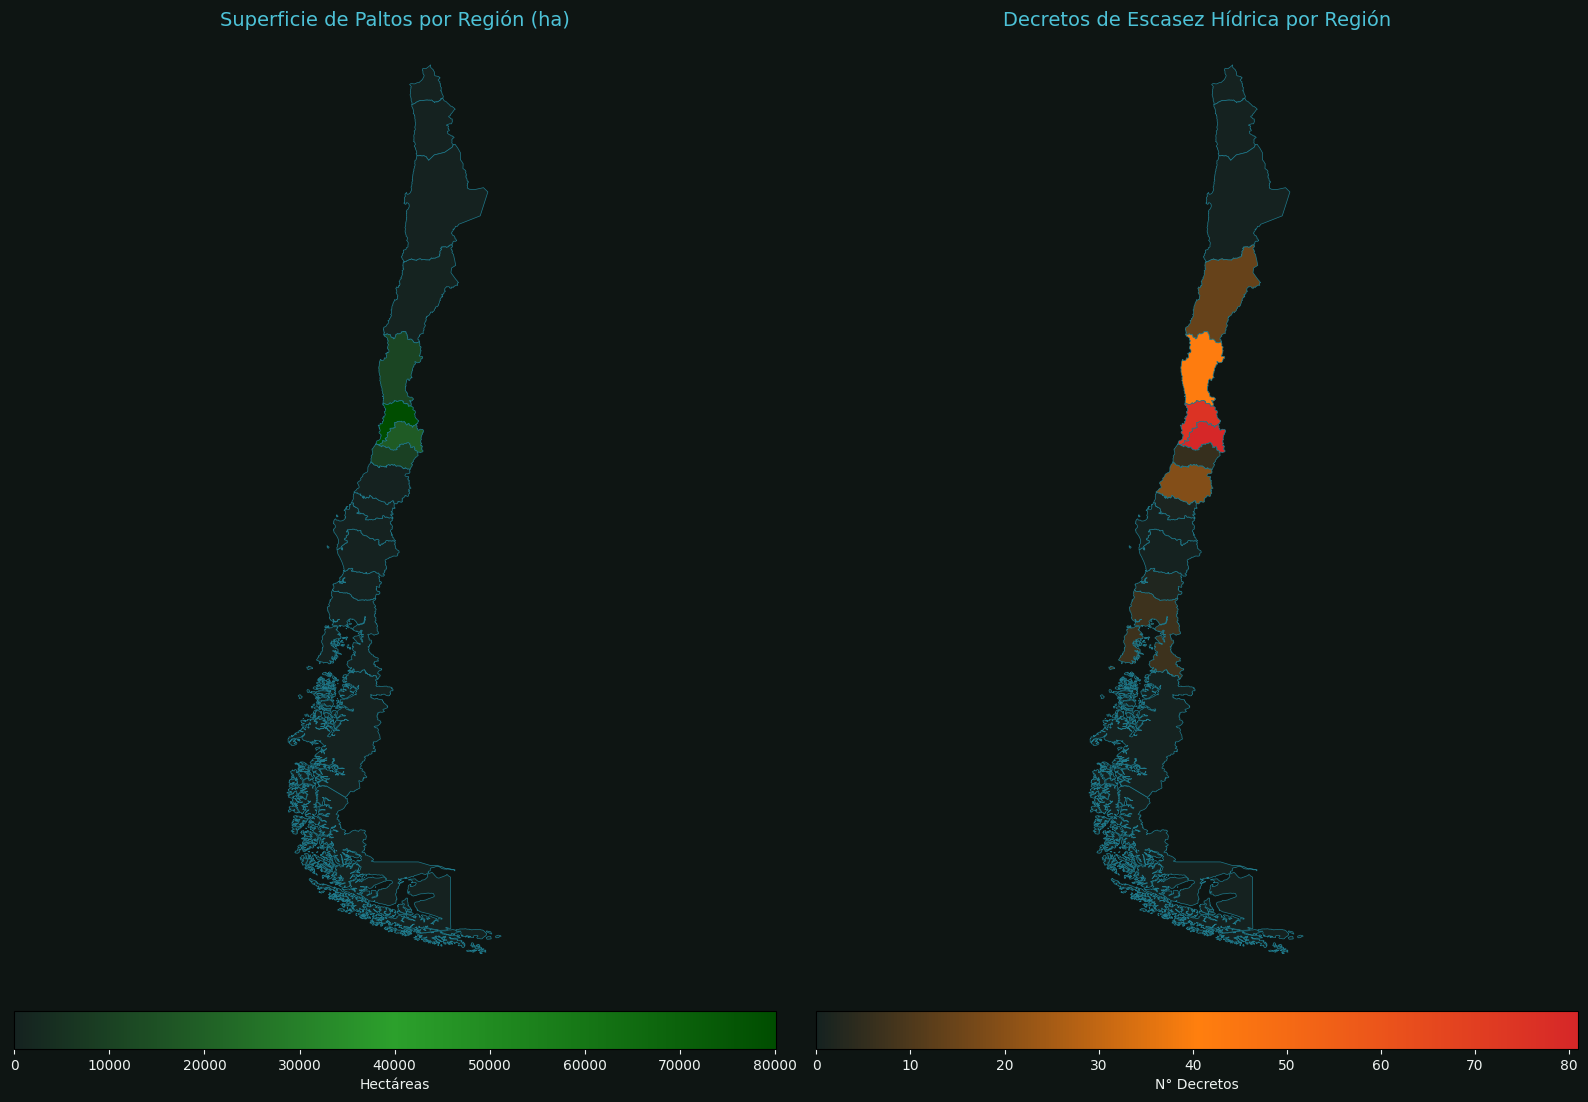

In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import urllib.request
import json

ruta_paltas = '../data/processed/catastro_paltas_2016_2025 (1).parquet'
ruta_escasez = '../data/processed/decretos_escasez_hidrica_limpio.xlsx'

df_paltas = pd.read_parquet(ruta_paltas)
df_escasez = pd.read_excel(ruta_escasez)

df_paltas['Superficie (ha)'] = df_paltas['Superficie (ha)'].astype(str).str.replace(',', '.').astype(float)

def limpiar_region(nombre):
    nombre = str(nombre).replace('Región de ', '').replace('Región del ', '').replace('Región ', '').strip()
    if 'Metropolitana' in nombre: return 'Metropolitana'
    if 'Higgins' in nombre: return "O'Higgins"
    if 'Biobío' in nombre or 'Bío Bío' in nombre: return 'Biobío'
    if 'Araucanía' in nombre: return 'La Araucanía'
    return nombre

df_paltas['Region_std'] = df_paltas['Region'].apply(limpiar_region)
paltas_region = df_paltas.groupby('Region_std')['Superficie (ha)'].sum().reset_index()

def extraer_regiones(texto):
    texto = str(texto).replace(' y ', ',')
    regiones = [r.strip() for r in texto.split(',') if r.strip()]
    regiones_std = []
    for r in regiones:
        if 'Metropolitana' in r: r = 'Metropolitana'
        elif 'Higgins' in r: r = "O'Higgins"
        elif 'Biobío' in r or 'Bío Bío' in r: r = 'Biobío'
        elif 'Araucanía' in r: r = 'La Araucanía'
        regiones_std.append(r)
    return regiones_std

df_escasez_exp = df_escasez.copy()
df_escasez_exp['Region_std'] = df_escasez_exp['Región'].apply(extraer_regiones)
df_escasez_exp = df_escasez_exp.explode('Region_std')
escasez_region = df_escasez_exp.groupby('Region_std')['ID decreto'].count().reset_index()
escasez_region = escasez_region.rename(columns={'ID decreto': 'Cantidad_Decretos'})

df_comparacion = pd.merge(paltas_region, escasez_region, on='Region_std', how='outer').fillna(0)

COLORES_BASE = {
    "titulos": "#4dc2d7",
    "subtitulos": "#1f7a8c",
    "letras": "#eef3f1",
    "fondo": "#0e1513",
    "cuadros": "#152220"
}

url_geojson = "https://raw.githubusercontent.com/caracena/chile-geojson/master/regiones.json"
req = urllib.request.Request(url_geojson, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(req) as response:
    chile_geojson = json.loads(response.read().decode())

gdf_chile = gpd.GeoDataFrame.from_features(chile_geojson)
gdf_chile['Region_std'] = gdf_chile['Region'].apply(limpiar_region)

gdf_completo = gdf_chile.merge(df_comparacion, on='Region_std', how='left').fillna(0)

cmap_paltas = LinearSegmentedColormap.from_list('Paltos', [COLORES_BASE['cuadros'], '#2ca02c', '#004d00'])
cmap_agua = LinearSegmentedColormap.from_list('Agua', [COLORES_BASE['cuadros'], '#ff7f0e', '#d62728'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 12))
fig.patch.set_facecolor(COLORES_BASE['fondo']) 

lon_min, lon_max = -76, -66
lat_min, lat_max = -56, -17

ax1.set_facecolor(COLORES_BASE['fondo']) 
gdf_completo.plot(
    column='Superficie (ha)', 
    ax=ax1, 
    cmap=cmap_paltas, 
    edgecolor=COLORES_BASE['subtitulos'], 
    linewidth=0.5,
    legend=True,
    legend_kwds={'label': "Hectáreas", 'orientation': "horizontal", 'pad': 0.05}
)
ax1.set_title('Superficie de Paltos por Región (ha)', color=COLORES_BASE['titulos'], fontsize=14, pad=20)
ax1.set_xlim(lon_min, lon_max)
ax1.set_ylim(lat_min, lat_max)
ax1.axis('off') 

ax2.set_facecolor(COLORES_BASE['fondo'])
gdf_completo.plot(
    column='Cantidad_Decretos', 
    ax=ax2, 
    cmap=cmap_agua, 
    edgecolor=COLORES_BASE['subtitulos'],
    linewidth=0.5,
    legend=True,
    legend_kwds={'label': "N° Decretos", 'orientation': "horizontal", 'pad': 0.05}
)
ax2.set_title('Decretos de Escasez Hídrica por Región', color=COLORES_BASE['titulos'], fontsize=14, pad=20)
ax2.set_xlim(lon_min, lon_max)
ax2.set_ylim(lat_min, lat_max)
ax2.axis('off')

for ax in fig.axes:
    if ax not in [ax1, ax2]:
        ax.xaxis.label.set_color(COLORES_BASE['letras'])
        ax.tick_params(axis='x', colors=COLORES_BASE['letras'])

plt.tight_layout()

ruta_imagen = '../visualizaciones/mapa_comparativo_paltas_vs_escasez.png'
plt.savefig(ruta_imagen, dpi=300, bbox_inches='tight', facecolor=COLORES_BASE['fondo'])

plt.show()